In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

##  Load and clean network traffic records. 

In [2]:
df=pd.read_csv("Downloads/network_traffic_pattern_analysis_messy.csv")
df

,Timestamp,Source IP,Destination IP,Protocol,Source Port,Destination Port,Packet Size,Bytes Transferred,Connection Status
0,2026-10-01 00:01:43,192.168.1.5,192.168.1.33,HTTP,56466.0,80.0,103.0,7416.0,Success
1,2026-10-01 00:02:04,192.168.1.13,203.0.113.3,NaN,50128.0,443.0,207.0,21321.0,Success
2,2026-10-01 00:04:06,192.168.1.27,198.51.100.16,TCP,62898.0,443.0,NaN,4248.0,Success
3,2026-10-01 00:06:17,192.168.1.22,203.0.113.22,HTTPS,58257.0,443.0,286.0,6292.0,Success
4,2026-10-01 00:07:10,192.168.1.50,NaN,TCP,60422.0,3306.0,101.0,2121.0,Success
...,...,...,...,...,...,...,...,...,...
1015,2026-10-01 11:01:29,10.0.0.33,198.51.100.5,TCP,62901.0,25.0,165.0,15180.0,Success
1016,2026-10-01 13:02:39,192.168.1.37,203.0.113.9,TCP,54425.0,3306.0,443.0,170112.0,Success
1017,2026-10-01 14:57:28,192.168.1.23,203.0.113.22,TCP,62974.0,NaN,288.0,13248.0,Success
1018,2026-10-01 20:36:33,192.168.1.35,198.51.100.12,TCP,64636.0,25.0,156.0,18096.0,Timeout


In [17]:
df.shape

(1020, 9)

In [18]:
df.size

9180

In [19]:
df.dtypes

Timestamp             object
Source IP             object
Destination IP        object
Protocol              object
Source Port          float64
Destination Port     float64
Packet Size          float64
Bytes Transferred    float64
Connection Status     object
dtype: object

In [21]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1020 entries, 0 to 1019
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Timestamp          1005 non-null   object 
 1   Source IP          995 non-null    object 
 2   Destination IP     999 non-null    object 
 3   Protocol           989 non-null    object 
 4   Source Port        1000 non-null   float64
 5   Destination Port   994 non-null    float64
 6   Packet Size        989 non-null    float64
 7   Bytes Transferred  985 non-null    float64
 8   Connection Status  995 non-null    object 
dtypes: float64(4), object(5)
memory usage: 71.8+ KB


In [22]:
df.describe()

,Source Port,Destination Port,Packet Size,Bytes Transferred
count,1000.00000,994.000000,989.000000,9.850000e+02
mean,57278.23500,7722.754527,210.687563,1.461039e+04
std,5047.54958,15651.121784,619.383849,4.835326e+04
min,-20.00000,-1.000000,-10.000000,-5.000000e+02
25%,53083.50000,67.000000,95.000000,3.640000e+03
50%,57599.00000,443.000000,152.000000,8.004000e+03
75%,61348.50000,8080.000000,224.000000,1.450000e+04
max,70000.00000,70000.000000,15000.000000,1.074150e+06


## check missing value 

In [8]:
df.isna().sum()

Timestamp            15
Source IP            25
Destination IP       21
Protocol             31
Source Port          20
Destination Port     26
Packet Size          31
Bytes Transferred    35
Connection Status    25
dtype: int64

## total missing value count 

In [9]:
df.isna().sum().sum()

np.int64(229)

## check if  any missing value in each column

In [10]:
df.isna().any()

Timestamp            True
Source IP            True
Destination IP       True
Protocol             True
Source Port          True
Destination Port     True
Packet Size          True
Bytes Transferred    True
Connection Status    True
dtype: bool

## check if all value are missing 

In [11]:
df.isna().all()

Timestamp            False
Source IP            False
Destination IP       False
Protocol             False
Source Port          False
Destination Port     False
Packet Size          False
Bytes Transferred    False
Connection Status    False
dtype: bool

## check missing value timestamp column

In [12]:
df["Timestamp"].isna().sum()

np.int64(15)

## count the non missing value 

In [13]:
df["Timestamp"].notna().sum()

np.int64(1005)

## display the missing value 

In [14]:
df[df["Timestamp"].isnull()]

,Timestamp,Source IP,Destination IP,Protocol,Source Port,Destination Port,Packet Size,Bytes Transferred,Connection Status
26,NaN,10.0.0.37,198.51.100.27,TCP,52732.0,443.0,53.0,3339.0,Success
79,NaN,10.0.0.12,10.0.0.3,HTTP,63424.0,8080.0,72.0,2520.0,Success
176,NaN,192.168.1.8,10.0.0.26,HTTP,60117.0,80.0,339.0,26103.0,Success
353,NaN,192.168.1.40,198.51.100.28,HTTPS,58131.0,443.0,139.0,3336.0,Success
361,NaN,192.168.1.37,203.0.113.16,TCP,58488.0,22.0,212.0,5300.0,Success
367,NaN,10.0.0.12,203.0.113.18,HTTP,51891.0,8080.0,250.0,11500.0,timeout
463,NaN,NaN,198.51.100.15,HTTPS,49287.0,443.0,91.0,6916.0,Timeout
632,NaN,10.0.0.14,192.168.1.34,TCP,60948.0,55001.0,69.0,4830.0,Success
639,NaN,192.168.1.31,10.0.0.21,TCP,49526.0,49152.0,82.0,1394.0,Success
703,NaN,10.0.0.10,203.0.113.20,UDP,50594.0,5353.0,NaN,13695.0,Timeout


In [15]:
df["Timestamp"].nunique()

985

## check duplicated value in a single column

In [16]:
df["Timestamp"].duplicated().sum()

np.int64(34)

## display the duplicated value 

In [17]:
df[df["Timestamp"].duplicated(keep=False)]

,Timestamp,Source IP,Destination IP,Protocol,Source Port,Destination Port,Packet Size,Bytes Transferred,Connection Status
1,2026-10-01 00:02:04,192.168.1.13,203.0.113.3,NaN,50128.0,443.0,207.0,21321.0,Success
26,NaN,10.0.0.37,198.51.100.27,TCP,52732.0,443.0,53.0,3339.0,Success
79,NaN,10.0.0.12,10.0.0.3,HTTP,63424.0,8080.0,72.0,2520.0,Success
92,2026-10-01 02:25:50,10.0.0.21,198.51.100.11,HTTPS,56547.0,8443.0,136.0,7208.0,Success
103,2026-10-01 02:40:55,192.168.1.53,10.0.0.14,TCP,50354.0,55001.0,1815.0,117975.0,Success
132,2026-10-01 03:30:28,10.0.0.2,198.51.100.19,ICMP,57742.0,0.0,43.0,688.0,Success
134,2026-10-01 03:30:54,10.0.0.33,203.0.113.27,UDP,52975.0,67.0,155.0,14105.0,Success
145,2026-10-01 03:49:20,10.0.0.5,192.168.1.56,TCP,52689.0,55001.0,117.0,12753.0,Success
176,NaN,192.168.1.8,10.0.0.26,HTTP,60117.0,80.0,339.0,26103.0,Success
237,2026-10-01 06:02:42,192.168.1.40,203.0.113.2,HTTPS,61222.0,8443.0,360.0,39240.0,Blocked


## check data type 

In [18]:
df["Timestamp"].dtype

dtype('O')

## convert datatype object to datetime

In [23]:
df["Timestamp"] = pd.to_datetime(
    df["Timestamp"], errors="coerce"
)

In [24]:
df["Timestamp"] = pd.to_datetime(df["Timestamp"])

print(df["Timestamp"].dtype)

datetime64[ns]


## Check Max & Min Network Traffic

In [25]:
print(df["Timestamp"].min())
print(df["Timestamp"].max())

2026-10-01 00:01:43
2026-10-02 01:19:56


## check max time spend in one day

In [26]:
date = pd.to_datetime("2026-10-01").date()

print(df.loc[df["Timestamp"].dt.date == date, "Timestamp"].max())

2026-10-01 23:58:53


## check min time spend in one day

In [23]:
date = pd.to_datetime("2026-10-01").date()

print(df.loc[df["Timestamp"].dt.date == date, "Timestamp"].min())

2026-10-01 00:01:43


## next day spend time check 

In [24]:
date = pd.to_datetime("2026-10-02").date()

print(df.loc[df["Timestamp"].dt.date == date, "Timestamp"].max())

2026-10-02 01:19:56


In [25]:
date = pd.to_datetime("2026-10-02").date()

print(df.loc[df["Timestamp"].dt.date == date, "Timestamp"].min())

2026-10-02 00:01:35


## check unique data timestamp column

In [26]:
print(df["Timestamp"].dt.date.unique())

[datetime.date(2026, 10, 1) NaT datetime.date(2026, 10, 2)]


## only valid date

In [27]:
print(df["Timestamp"].dt.date.dropna().unique())

[datetime.date(2026, 10, 1) datetime.date(2026, 10, 2)]


## count the valid date

In [28]:
print(df["Timestamp"].dt.date.value_counts().sort_index())

Timestamp
2026-10-01    953
2026-10-02     52
Name: count, dtype: int64


In [29]:
df["Timestamp"].is_monotonic_increasing

False

In [30]:
print(df.columns)

Index(['Timestamp', 'Source IP', 'Destination IP', 'Protocol', 'Source Port',
       'Destination Port', 'Packet Size', 'Bytes Transferred',
       'Connection Status'],
      dtype='object')


# CHECK SECOND COLUMN 

In [31]:
df["Source IP"].dtype

dtype('O')

In [32]:
df["Source IP"].isnull().sum()

np.int64(25)

In [33]:
df[df["Source IP"].isnull()]

,Timestamp,Source IP,Destination IP,Protocol,Source Port,Destination Port,Packet Size,Bytes Transferred,Connection Status
12,2026-10-01 00:19:37,NaN,203.0.113.4,TCP,52744.0,80.0,40.0,3600.0,Failed
90,2026-10-01 02:20:20,NaN,10.0.0.5,DNS,52890.0,53.0,152.0,2584.0,Success
143,2026-10-01 03:45:31,NaN,198.51.100.19,TCP,51234.0,55001.0,64.0,2176.0,Success
154,2026-10-01 04:02:32,NaN,NaN,TCP,63213.0,22.0,149.0,16688.0,Success
165,2026-10-01 04:18:18,NaN,198.51.100.26,HTTP,52620.0,80.0,204.0,9384.0,Success
195,2026-10-01 05:08:55,NaN,10.0.0.14,UDP,49818.0,161.0,48.0,2688.0,Success
223,2026-10-01 05:45:39,NaN,198.51.100.21,HTTPS,62802.0,443.0,80.0,4480.0,Success
268,2026-10-01 06:50:41,NaN,192.168.1.10,ICMP,64620.0,0.0,140.0,10220.0,Success
273,2026-10-01 06:58:47,NaN,10.0.0.36,TCP,52849.0,22.0,100.0,7600.0,Success
332,2026-10-01 08:35:45,NaN,203.0.113.23,UDP,60685.0,NaN,50.0,5750.0,Success


In [34]:
print(df["Source IP"].nunique())

96


In [35]:
df["Source IP"].duplicated().sum()

np.int64(923)

In [36]:
print(df["Source IP"].value_counts().head(50))

Source IP
10.0.0.2        18
192.168.1.50    18
192.168.1.53    18
10.0.0.22       17
10.0.0.4        17
192.168.1.40    17
10.0.0.17       17
192.168.1.37    16
192.168.1.35    15
192.168.1.24    15
10.0.0.12       15
10.0.0.33       15
192.168.1.19    15
10.0.0.21       14
192.168.1.27    14
10.0.0.32       14
192.168.1.22    14
192.168.1.30    13
192.168.1.43    13
10.0.0.8        13
192.168.1.49    13
10.0.0.6        13
192.168.1.48    13
10.0.0.14       13
192.168.1.39    13
192.168.1.42    13
10.0.0.11       13
192.168.1.23    13
10.0.0.28       12
192.168.1.14    12
10.0.0.15       12
192.168.1.16    12
192.168.1.4     12
192.168.1.29    12
192.168.1.58    12
192.168.1.11    12
192.168.1.33    12
10.0.0.7        11
192.168.1.21    11
192.168.1.32    11
192.168.1.3     11
10.0.0.5        11
10.0.0.30       11
192.168.1.5     11
192.168.1.15    11
10.0.0.37       11
192.168.1.36    11
192.168.1.47    11
10.0.0.27       11
10.0.0.38       11
Name: count, dtype: int64


In [37]:
df[df["Source IP"].duplicated()]

,Timestamp,Source IP,Destination IP,Protocol,Source Port,Destination Port,Packet Size,Bytes Transferred,Connection Status
5,2026-10-01 00:09:51,192.168.1.50,203.0.113.19,ICMP,61002.0,0.0,97.0,2134.0,Success
19,2026-10-01 00:29:29,10.0.0.12,192.168.1.18,DNS,64726.0,53.0,59.0,5310.0,Timeout
32,2026-10-01 00:47:34,10.0.0.11,198.51.100.4,HTTPS,51777.0,NaN,326.0,NaN,Success
33,2026-10-01 00:49:18,192.168.1.53,198.51.100.28,HTTPS,57219.0,443.0,330.0,28380.0,Success
36,2026-10-01 00:52:09,192.168.1.11,198.51.100.4,DNS,57842.0,53.0,392.0,NaN,Timeout
...,...,...,...,...,...,...,...,...,...
1015,2026-10-01 11:01:29,10.0.0.33,198.51.100.5,TCP,62901.0,25.0,165.0,15180.0,Success
1016,2026-10-01 13:02:39,192.168.1.37,203.0.113.9,TCP,54425.0,3306.0,443.0,170112.0,Success
1017,2026-10-01 14:57:28,192.168.1.23,203.0.113.22,TCP,62974.0,NaN,288.0,13248.0,Success
1018,2026-10-01 20:36:33,192.168.1.35,198.51.100.12,TCP,64636.0,25.0,156.0,18096.0,Timeout


## Third column

In [38]:
df["Destination IP"].dtypes

dtype('O')

In [39]:
df["Destination IP"].isnull().sum()

np.int64(21)

In [40]:
df["Destination IP"].duplicated().sum()

np.int64(868)

In [41]:
df["Destination IP"].nunique()

151

In [42]:
print(df["Destination IP"].value_counts())

Destination IP
198.51.100.3     20
198.51.100.19    20
198.51.100.6     20
203.0.113.9      18
198.51.100.21    18
                 ..
10.0.0.13         1
192.168.1.35      1
192.168.1.25      1
192.168.1.36      1
10.0.0.27         1
Name: count, Length: 151, dtype: int64


In [43]:
print(df["Destination IP"].value_counts().head(60))

Destination IP
198.51.100.3     20
198.51.100.19    20
198.51.100.6     20
203.0.113.9      18
198.51.100.21    18
198.51.100.16    17
198.51.100.23    16
203.0.113.1      16
198.51.100.10    16
198.51.100.20    16
198.51.100.9     15
198.51.100.17    15
198.51.100.28    15
203.0.113.4      15
203.0.113.23     15
198.51.100.15    15
203.0.113.13     15
203.0.113.2      14
203.0.113.20     14
198.51.100.8     14
203.0.113.8      13
203.0.113.18     13
203.0.113.14     13
203.0.113.3      13
198.51.100.2     12
198.51.100.13    12
203.0.113.6      12
203.0.113.27     12
198.51.100.18    12
198.51.100.24    12
203.0.113.24     12
198.51.100.29    12
203.0.113.10     12
198.51.100.11    11
198.51.100.7     11
203.0.113.7      11
203.0.113.17     10
203.0.113.5      10
198.51.100.26    10
203.0.113.19     10
198.51.100.27    10
198.51.100.1     10
203.0.113.11     10
203.0.113.25     10
198.51.100.14    10
203.0.113.16     10
198.51.100.12     9
198.51.100.25     9
203.0.113.22      9
203.0

In [44]:
df.columns

Index(['Timestamp', 'Source IP', 'Destination IP', 'Protocol', 'Source Port',
       'Destination Port', 'Packet Size', 'Bytes Transferred',
       'Connection Status'],
      dtype='object')

## fourth column

In [165]:
df["Protocol"].dtype

dtype('O')

In [141]:
df["Protocol"].isnull().sum()

np.int64(30)

In [142]:
df["Protocol"].unique()

array(['HTTP', nan, 'TCP', 'HTTPS', 'ICMP', 'UDP', 'DNS', 'HTTPS ',
       'DNS ', 'dns', ' UDP', 'HTTP ', 'TCP ', ' TCP'], dtype=object)

## Remove extra space

In [166]:
df["Protocol"]=df["Protocol"].str.strip()

## convert all value in upper case 

In [167]:
df["Protocol"]=df["Protocol"].str.upper()

## fill nan value 

In [168]:
df["Protocol"] = df["Protocol"].fillna("Unknown")

In [169]:
print(df["Protocol"].unique())

['HTTP' 'UNKNOWN' 'TCP' 'HTTPS' 'ICMP' 'UDP' 'DNS']


In [170]:
print(df["Protocol"].nunique())

7


In [147]:
df["Protocol"].isna().sum()

np.int64(0)

## six column

In [53]:
df["Source Port"].dtypes

dtype('float64')

In [54]:
df["Source Port"].isna().sum()

np.int64(20)

In [55]:
df[df["Source Port"].isnull()]

,Timestamp,Source IP,Destination IP,Protocol,Source Port,Destination Port,Packet Size,Bytes Transferred,Connection Status
69,2026-10-01 01:46:24,192.168.1.12,203.0.113.9,HTTP,NaN,80.0,40.0,440.0,Success
77,2026-10-01 02:00:13,10.0.0.8,NaN,UDP,NaN,49153.0,474.0,11850.0,Success
170,2026-10-01 04:28:56,10.0.0.4,203.0.113.20,UDP,NaN,500.0,96.0,2976.0,Success
185,2026-10-01 04:54:05,192.168.1.50,203.0.113.27,HTTPS,NaN,443.0,497.0,1491.0,Success
242,2026-10-01 06:09:48,10.0.0.38,10.0.0.34,DNS,NaN,53.0,97.0,4268.0,Blocked
252,2026-10-01 06:24:20,10.0.0.27,198.51.100.6,HTTPS,NaN,443.0,115.0,7130.0,Failed
298,2026-10-01 07:35:54,192.168.1.9,198.51.100.16,ICMP,NaN,0.0,169.0,4563.0,Success
457,2026-10-01 11:40:37,192.168.1.11,203.0.113.13,DNS,NaN,53.0,114.0,NaN,Success
544,2026-10-01 13:49:54,192.168.1.19,203.0.113.15,TCP,NaN,3306.0,393.0,25152.0,Success
553,2026-10-01 14:00:28,10.0.0.12,203.0.113.8,HTTP,NaN,8080.0,75.0,5175.0,Timeout


In [56]:
df["Source Port"].duplicated().sum()

np.int64(63)

In [57]:
df["Source Port"].unique()

array([ 5.6466e+04,  5.0128e+04,  6.2898e+04,  5.8257e+04,  6.0422e+04,
        6.1002e+04,  6.1607e+04,  5.1491e+04,  5.6348e+04,  5.7925e+04,
        6.2116e+04,  6.3190e+04,  5.2744e+04,  6.4489e+04,  5.7895e+04,
        5.5006e+04,  5.4160e+04,  5.9773e+04,  5.1732e+04,  6.4726e+04,
        5.5743e+04,  5.3117e+04,  5.1478e+04,  6.5058e+04,  6.4650e+04,
        5.0927e+04,  5.2732e+04,  5.1622e+04,  5.2208e+04,  6.1570e+04,
        6.5099e+04,  5.9428e+04,  5.1777e+04,  5.7219e+04,  5.5845e+04,
        5.1529e+04,  5.7842e+04,  5.9064e+04,  5.7818e+04,  6.0387e+04,
        5.2176e+04,  5.4446e+04,  5.4036e+04,  5.0459e+04,  5.4216e+04,
        6.0037e+04,  5.2694e+04,  5.6609e+04,  6.0658e+04,  5.5003e+04,
        5.2941e+04,  5.5608e+04,  5.3235e+04,  5.5438e+04,  6.2458e+04,
        6.3628e+04,  5.8451e+04,  5.3980e+04,  5.5523e+04,  6.3083e+04,
        5.3128e+04,  6.3654e+04,  5.7253e+04,  5.8514e+04,  5.4159e+04,
        4.9792e+04,  6.2882e+04,  6.3433e+04,  5.3334e+04,      

In [58]:
df["Source Port"].nunique()

956

## check invalid data 

In [59]:
df[df["Source Port"]<0]

,Timestamp,Source IP,Destination IP,Protocol,Source Port,Destination Port,Packet Size,Bytes Transferred,Connection Status
236,2026-10-01 06:00:32,10.0.0.22,192.168.1.40,UDP,-20.0,500.0,55.0,4840.0,Success


In [60]:
(df["Source Port"]<0).sum()

np.int64(1)

## check frequncy

In [61]:
df["Source Port"].value_counts().head(50)

Source Port
54425.0    2
58673.0    2
55760.0    2
60022.0    2
55292.0    2
62458.0    2
57627.0    2
59391.0    2
65126.0    2
50536.0    2
52077.0    2
51881.0    2
64379.0    2
51957.0    2
62901.0    2
55218.0    2
62974.0    2
56547.0    2
64636.0    2
51775.0    2
59808.0    2
54953.0    2
58488.0    2
60225.0    2
50354.0    2
52563.0    2
65116.0    2
61137.0    2
57742.0    2
52975.0    2
58539.0    2
51561.0    2
52689.0    2
60989.0    2
60208.0    2
59690.0    2
49526.0    2
61593.0    2
61222.0    2
49428.0    2
61879.0    2
63101.0    2
56123.0    2
50128.0    2
64512.0    1
62540.0    1
55855.0    1
64144.0    1
58615.0    1
50413.0    1
Name: count, dtype: int64

In [62]:
df[df["Source Port"]==0]

,Timestamp,Source IP,Destination IP,Protocol,Source Port,Destination Port,Packet Size,Bytes Transferred,Connection Status


## check valid range

In [63]:
df[df["Source Port"] >65535]

,Timestamp,Source IP,Destination IP,Protocol,Source Port,Destination Port,Packet Size,Bytes Transferred,Connection Status
873,2026-10-01 21:54:56,192.168.1.6,203.0.113.18,UDP,70000.0,53.0,94.0,282.0,Failed


In [64]:
df[
    df["Source Port"].notna() &
    (df["Source Port"]%1 !=0)
]

,Timestamp,Source IP,Destination IP,Protocol,Source Port,Destination Port,Packet Size,Bytes Transferred,Connection Status


## Statistical summary

In [65]:
df["Source Port"].describe()

count     1000.00000
mean     57278.23500
std       5047.54958
min        -20.00000
25%      53083.50000
50%      57599.00000
75%      61348.50000
max      70000.00000
Name: Source Port, dtype: float64

In [66]:
print(df.groupby("Protocol")["Source Port"].describe())

          count          mean          std      min       25%      50%  \
Protocol                                                                 
DNS        83.0  58004.132530  4535.819110  49293.0  54241.50  57842.0   
HTTP      132.0  56744.719697  4690.267797  49477.0  52413.75  56403.0   
HTTPS     211.0  57438.900474  4730.964634  49169.0  53321.50  57992.0   
ICMP       43.0  58133.441860  4167.886162  50187.0  54866.00  58154.0   
TCP       334.0  56998.823353  4672.290010  49158.0  52689.00  57184.0   
UDP       166.0  57373.433735  6689.545291    -20.0  53380.75  57654.5   
Unknown    31.0  57827.290323  4637.646330  49157.0  55261.50  59064.0   

               75%      max  
Protocol                     
DNS       62158.50  65275.0  
HTTP      60323.75  65343.0  
HTTPS     61334.50  65318.0  
ICMP      60955.50  65281.0  
TCP       61118.00  65439.0  
UDP       61859.25  70000.0  
Unknown   60181.50  65532.0  


In [67]:
df.columns

Index(['Timestamp', 'Source IP', 'Destination IP', 'Protocol', 'Source Port',
       'Destination Port', 'Packet Size', 'Bytes Transferred',
       'Connection Status'],
      dtype='object')

## Distination column

In [68]:
df["Destination Port"].dtype

dtype('float64')

In [69]:
df["Destination Port"].unique()

array([ 8.0000e+01,  4.4300e+02,  3.3060e+03,  0.0000e+00,  5.3530e+03,
        2.5000e+01,  8.4430e+03,  5.0000e+02,  5.3000e+01,  8.0800e+03,
        5.5001e+04,         nan,  2.2000e+01,  4.9152e+04,  1.6100e+02,
        4.9153e+04,  6.7000e+01,  1.2300e+02,  7.0000e+04, -1.0000e+00])

In [70]:
df["Destination Port"].nunique()

19

In [71]:
df["Destination Port"].isna().sum()

np.int64(26)

In [72]:
print(df[df["Destination Port"].isna()])

               Timestamp     Source IP Destination IP Protocol  Source Port  \
29   2026-10-01 00:42:00  192.168.1.53   192.168.1.23      TCP      61570.0   
32   2026-10-01 00:47:34     10.0.0.11   198.51.100.4    HTTPS      51777.0   
83   2026-10-01 02:12:04     10.0.0.32  198.51.100.17    HTTPS      65235.0   
126  2026-10-01 03:18:15  192.168.1.31   203.0.113.23    HTTPS      56328.0   
231  2026-10-01 05:55:26  192.168.1.19      10.0.0.37      TCP      61137.0   
277  2026-10-01 07:02:08  192.168.1.32   203.0.113.10    HTTPS      56395.0   
314  2026-10-01 08:02:46  192.168.1.44   192.168.1.50      DNS      59950.0   
330  2026-10-01 08:32:27  192.168.1.29  198.51.100.20      TCP      51202.0   
332  2026-10-01 08:35:45           NaN   203.0.113.23      UDP      60685.0   
352  2026-10-01 09:07:25  192.168.1.22    203.0.113.1      TCP      63170.0   
419  2026-10-01 10:47:19     10.0.0.14      10.0.0.37      UDP      57844.0   
420  2026-10-01 10:47:30     10.0.0.17   198.51.100.

In [73]:
df["Destination Port"].duplicated().sum()

np.int64(1000)

In [74]:
df["Destination Port"].value_counts()

Destination Port
 443.0      158
 8080.0     116
 53.0       106
 80.0       101
 8443.0      99
 25.0        51
 3306.0      47
 55001.0     46
 0.0         43
 22.0        40
 49152.0     34
 500.0       28
 123.0       28
 5353.0      26
 161.0       26
 49153.0     25
 67.0        18
 70000.0      1
-1.0          1
Name: count, dtype: int64

In [75]:
print("min value",df["Destination Port"].min())
print("max value",df["Destination Port"].max())

min value -1.0
max value 70000.0


## check invalid data (negative value)

In [76]:
print(df[df["Destination Port"] < 0])

               Timestamp  Source IP Destination IP Protocol  Source Port  \
1003 2026-10-01 03:30:54  10.0.0.33   203.0.113.27      UDP      52975.0   

      Destination Port  Packet Size  Bytes Transferred Connection Status  
1003              -1.0        155.0            14105.0           Success  


## check port 65535 grater then 

In [77]:
print(df[df["Destination Port"] > 65535])

              Timestamp  Source IP Destination IP Protocol  Source Port  \
515 2026-10-01 13:08:03  10.0.0.22   192.168.1.33    HTTPS      50458.0   

     Destination Port  Packet Size  Bytes Transferred Connection Status  
515           70000.0          NaN            12848.0            Failed  


In [78]:
print(df[df["Destination Port"] == 0])

               Timestamp     Source IP Destination IP Protocol  Source Port  \
5    2026-10-01 00:09:51  192.168.1.50   203.0.113.19     ICMP      61002.0   
61   2026-10-01 01:30:04     10.0.0.15  198.51.100.20     ICMP      63654.0   
64   2026-10-01 01:36:28  192.168.1.19   203.0.113.25     ICMP      54159.0   
109  2026-10-01 02:52:10  192.168.1.51  198.51.100.10     ICMP      53625.0   
129  2026-10-01 03:25:16  192.168.1.48   203.0.113.18     ICMP      54543.0   
132  2026-10-01 03:30:28      10.0.0.2  198.51.100.19     ICMP      57742.0   
167  2026-10-01 04:22:41  192.168.1.26   192.168.1.46     ICMP      60656.0   
184  2026-10-01 04:52:07  192.168.1.41       10.0.0.4     ICMP      55509.0   
221  2026-10-01 05:40:56  192.168.1.18  198.51.100.11     ICMP      52213.0   
245  2026-10-01 06:12:15  192.168.1.30   192.168.1.40     ICMP      58622.0   
246  2026-10-01 06:14:06     10.0.0.36    203.0.113.8     ICMP      61593.0   
255  2026-10-01 06:30:58      10.0.0.7   192.168.1.1

In [79]:
print(df["Destination Port"].describe())

count      994.000000
mean      7722.754527
std      15651.121784
min         -1.000000
25%         67.000000
50%        443.000000
75%       8080.000000
max      70000.000000
Name: Destination Port, dtype: float64


In [80]:
df.columns

Index(['Timestamp', 'Source IP', 'Destination IP', 'Protocol', 'Source Port',
       'Destination Port', 'Packet Size', 'Bytes Transferred',
       'Connection Status'],
      dtype='object')

## 7th column( Packet size)

In [81]:
df["Packet Size"].dtype

dtype('float64')

In [82]:
df["Packet Size"].size

1020

In [83]:
df["Packet Size"].nunique()

350

In [84]:
df["Packet Size"].isna().sum()

np.int64(31)

In [85]:
print(df[df["Packet Size"].isna()])

               Timestamp     Source IP Destination IP Protocol  Source Port  \
2    2026-10-01 00:04:06  192.168.1.27  198.51.100.16      TCP      62898.0   
44   2026-10-01 01:02:17     10.0.0.15   192.168.1.54      TCP      54216.0   
64   2026-10-01 01:36:28  192.168.1.19   203.0.113.25     ICMP      54159.0   
100  2026-10-01 02:39:19     10.0.0.30      10.0.0.17      TCP      49831.0   
113  2026-10-01 02:57:41  192.168.1.42      10.0.0.34      UDP      61644.0   
135  2026-10-01 03:32:18  192.168.1.16  198.51.100.28      DNS      53597.0   
210  2026-10-01 05:30:18  192.168.1.52   203.0.113.18      UDP      57331.0   
216  2026-10-01 05:37:08     10.0.0.14  198.51.100.28    HTTPS      51977.0   
241  2026-10-01 06:09:20  192.168.1.58   203.0.113.10      TCP      62683.0   
338  2026-10-01 08:47:02  192.168.1.23    203.0.113.2      UDP      56378.0   
350  2026-10-01 09:04:15  192.168.1.29   203.0.113.21      DNS      58444.0   
370  2026-10-01 09:31:39     10.0.0.28   192.168.1.1

In [86]:
df["Packet Size"].duplicated().sum()

np.int64(669)

In [87]:
print(df["Packet Size"].min())
print(df["Packet Size"].max())

-10.0
15000.0


In [88]:
print(df[df["Packet Size"] < 0])

              Timestamp     Source IP Destination IP Protocol  Source Port  \
7   2026-10-01 00:11:35  192.168.1.47   203.0.113.18      TCP      51491.0   
932 2026-10-01 23:32:07  192.168.1.59   203.0.113.13      UDP          NaN   

     Destination Port  Packet Size  Bytes Transferred Connection Status  
7                80.0        -10.0             3410.0           Success  
932             500.0         -1.0            13231.0           Success  


In [89]:
print((df["Packet Size"] < 0).sum())

2


In [90]:
print(df["Packet Size"].describe())

count      989.000000
mean       210.687563
std        619.383849
min        -10.000000
25%         95.000000
50%        152.000000
75%        224.000000
max      15000.000000
Name: Packet Size, dtype: float64


In [91]:
print(df["Packet Size"].value_counts().head(10))

Packet Size
40.0     25
88.0     11
94.0     10
84.0     10
62.0     10
156.0     9
117.0     9
79.0      9
173.0     9
152.0     8
Name: count, dtype: int64


In [92]:
print(df.groupby("Protocol")["Packet Size"].mean())

Protocol
DNS        183.209877
HTTP       292.823077
HTTPS      198.355450
ICMP       112.000000
TCP        228.496970
UDP        168.374233
Unknown    191.774194
Name: Packet Size, dtype: float64


In [93]:
df.columns

Index(['Timestamp', 'Source IP', 'Destination IP', 'Protocol', 'Source Port',
       'Destination Port', 'Packet Size', 'Bytes Transferred',
       'Connection Status'],
      dtype='object')

## 8th column bytes transferred

In [94]:
df["Bytes Transferred"].dtype

dtype('float64')

In [95]:
df["Bytes Transferred"].nunique()

898

In [96]:
df["Bytes Transferred"].isna().sum()

np.int64(35)

In [97]:
print(df[df["Bytes Transferred"].isna()])

              Timestamp     Source IP Destination IP Protocol  Source Port  \
29  2026-10-01 00:42:00  192.168.1.53   192.168.1.23      TCP      61570.0   
32  2026-10-01 00:47:34     10.0.0.11   198.51.100.4    HTTPS      51777.0   
36  2026-10-01 00:52:09  192.168.1.11   198.51.100.4      DNS      57842.0   
41  2026-10-01 00:57:17  192.168.1.18   203.0.113.17      TCP      54446.0   
73  2026-10-01 01:52:23  192.168.1.16   203.0.113.14      UDP      64390.0   
118 2026-10-01 03:04:12  192.168.1.38      10.0.0.39     HTTP      52113.0   
150 2026-10-01 03:57:15  192.168.1.21   198.51.100.2      UDP      51351.0   
167 2026-10-01 04:22:41  192.168.1.26   192.168.1.46     ICMP      60656.0   
173 2026-10-01 04:31:22     10.0.0.21   203.0.113.10      TCP      51179.0   
204 2026-10-01 05:23:05  192.168.1.39    203.0.113.6      TCP      59897.0   
232 2026-10-01 05:57:27  192.168.1.26   203.0.113.19     HTTP      51561.0   
251 2026-10-01 06:22:28      10.0.0.5  198.51.100.20    HTTPS   

In [98]:
df["Bytes Transferred"].duplicated().sum()

np.int64(121)

In [99]:
print(df["Bytes Transferred"].value_counts().head(10))

Bytes Transferred
4040.0     3
5148.0     3
3680.0     3
11433.0    3
1440.0     3
2160.0     3
12420.0    3
12753.0    3
3600.0     3
1848.0     2
Name: count, dtype: int64


In [100]:
print(df["Bytes Transferred"].min())
print(df["Bytes Transferred"].max())

-500.0
1074150.0


In [101]:
print(df[df["Bytes Transferred"] < 0])

              Timestamp     Source IP Destination IP Protocol  Source Port  \
51  2026-10-01 01:13:53  192.168.1.57  198.51.100.23      TCP      55608.0   
472 2026-10-01 12:00:30     10.0.0.21   203.0.113.17      UDP      55760.0   
950 2026-10-02 00:01:35     10.0.0.35   192.168.1.48      TCP      57194.0   

     Destination Port  Packet Size  Bytes Transferred Connection Status  
51             8080.0        112.0               -1.0           Timeout  
472             123.0        196.0             -500.0           Success  
950              80.0        177.0             -250.0           Success  


In [102]:
print((df["Bytes Transferred"] < 0).sum())

3


In [103]:
print(df["Bytes Transferred"].describe())

count    9.850000e+02
mean     1.461039e+04
std      4.835326e+04
min     -5.000000e+02
25%      3.640000e+03
50%      8.004000e+03
75%      1.450000e+04
max      1.074150e+06
Name: Bytes Transferred, dtype: float64


In [104]:
df.columns

Index(['Timestamp', 'Source IP', 'Destination IP', 'Protocol', 'Source Port',
       'Destination Port', 'Packet Size', 'Bytes Transferred',
       'Connection Status'],
      dtype='object')

## connection status

In [150]:
df["Connection Status"].dtype

dtype('O')

In [151]:
df["Connection Status"].unique()

array(['Success', 'Failed', 'Timeout', 'Blocked', nan], dtype=object)

In [152]:
df["Connection Status"] = df["Connection Status"].str.strip().str.title()

In [153]:
print(df["Connection Status"].unique())

['Success' 'Failed' 'Timeout' 'Blocked' nan]


In [154]:
print(df["Connection Status"].isnull().sum())

25


In [157]:
df["Connection Status"] = df["Connection Status"].fillna("Unknown")

In [158]:
df["Connection Status"].unique()

array(['Success', 'Failed', 'Timeout', 'Blocked', 'Unknown'], dtype=object)

In [159]:
print(df["Connection Status"].value_counts())
print(df["Connection Status"].isnull().sum())

Connection Status
Success    739
Failed     103
Timeout     69
Blocked     51
Unknown     25
Name: count, dtype: int64
0


## data cleaning process()

In [34]:
df.isna().sum()

Timestamp            15
Source IP            25
Destination IP       21
Protocol             31
Source Port          20
Destination Port     26
Packet Size          31
Bytes Transferred    35
Connection Status    25
dtype: int64

## check overall missing value

In [36]:
df.isna().sum().sum()

np.int64(229)

## check overall duplicated value

In [37]:
df.duplicated().sum()

np.int64(18)

## check percentage of missing value in each column

In [38]:
print(df.isna().mean() * 100)


Timestamp            1.470588
Source IP            2.450980
Destination IP       2.058824
Protocol             3.039216
Source Port          1.960784
Destination Port     2.549020
Packet Size          3.039216
Bytes Transferred    3.431373
Connection Status    2.450980
dtype: float64


## percentage of missng value overall dataset

In [39]:
total_missing_value=df.isna().sum().sum()
total_cells=df.shape[0]*df.shape[1]
percentage=(total_missing_value/total_cells)*100
print("Overall Missing Values Percentage:", percentage, "%")

Overall Missing Values Percentage: 2.494553376906318 %


## handle missing value 

In [40]:
df["Timestamp"].isna().sum()

np.int64(15)

In [41]:
df["Timestamp"].duplicated().sum()

np.int64(34)

In [42]:
print(df["Timestamp"].isna().any())

True


In [43]:
print(df.loc[df["Timestamp"].isna(), ["Timestamp"]])

    Timestamp
26        NaN
79        NaN
176       NaN
353       NaN
361       NaN
367       NaN
463       NaN
632       NaN
639       NaN
703       NaN
721       NaN
788       NaN
827       NaN
839       NaN
904       NaN


In [44]:
print("Missing timestamps:", df["Timestamp"].isna().sum())

Missing timestamps: 15


In [45]:
df = df.dropna(subset=["Timestamp"])

In [46]:
print("Missing timestamps:", df["Timestamp"].isna().sum())
print("Dataset shape:", df.shape)

Missing timestamps: 0
Dataset shape: (1005, 9)


In [47]:
print(df[df["Timestamp"].duplicated(keep=False)].sort_values("Timestamp"))

                Timestamp     Source IP Destination IP Protocol  Source Port  \
1     2026-10-01 00:02:04  192.168.1.13    203.0.113.3      NaN      50128.0   
1014  2026-10-01 00:02:04  192.168.1.13    203.0.113.3      NaN      50128.0   
92    2026-10-01 02:25:50     10.0.0.21  198.51.100.11    HTTPS      56547.0   
1006  2026-10-01 02:25:50     10.0.0.21  198.51.100.11    HTTPS      56547.0   
103   2026-10-01 02:40:55  192.168.1.53      10.0.0.14      TCP      50354.0   
1012  2026-10-01 02:40:55  192.168.1.53      10.0.0.14      TCP      50354.0   
1001  2026-10-01 03:30:28      10.0.0.2  198.51.100.19     ICMP      57742.0   
132   2026-10-01 03:30:28      10.0.0.2  198.51.100.19     ICMP      57742.0   
1003  2026-10-01 03:30:54     10.0.0.33   203.0.113.27      UDP      52975.0   
134   2026-10-01 03:30:54     10.0.0.33   203.0.113.27      UDP      52975.0   
1005  2026-10-01 03:49:20      10.0.0.5   192.168.1.56      TCP      52689.0   
145   2026-10-01 03:49:20      10.0.0.5 

In [48]:
print("Duplicate timestamps:", df["Timestamp"].duplicated().sum())

Duplicate timestamps: 20


In [49]:
print("Complete duplicate rows:", df.duplicated().sum())

Complete duplicate rows: 18


In [50]:
df_backup = df.copy()

In [51]:
df = df.drop_duplicates()

In [52]:
print("Complete duplicate rows:", df.duplicated().sum())
print("Dataset shape:", df.shape)

Complete duplicate rows: 0
Dataset shape: (987, 9)


In [53]:
print(df[df["Timestamp"].duplicated(keep=False)].sort_values("Timestamp"))

                Timestamp  Source IP Destination IP Protocol  Source Port  \
134   2026-10-01 03:30:54  10.0.0.33   203.0.113.27      UDP      52975.0   
1003  2026-10-01 03:30:54  10.0.0.33   203.0.113.27      UDP      52975.0   
472   2026-10-01 12:00:30  10.0.0.21   203.0.113.17      UDP      55760.0   
1009  2026-10-01 12:00:30  10.0.0.21   203.0.113.17      UDP      55760.0   

      Destination Port  Packet Size  Bytes Transferred Connection Status  
134               67.0        155.0            14105.0           Success  
1003              -1.0        155.0            14105.0           Success  
472              123.0        196.0             -500.0           Success  
1009             123.0        196.0            19796.0           Success  


In [54]:
print("Missing timestamps:", df["Timestamp"].isna().sum())

Missing timestamps: 0


In [55]:
print(df["Timestamp"].duplicated().sum())

2


In [56]:
print(df[df.duplicated(keep=False)])

Empty DataFrame
Columns: [Timestamp, Source IP, Destination IP, Protocol, Source Port, Destination Port, Packet Size, Bytes Transferred, Connection Status]
Index: []


In [57]:
df = df.drop_duplicates()

In [58]:
print("Missing timestamps:", df["Timestamp"].isna().sum())
print("Duplicate rows:", df.duplicated().sum())

Missing timestamps: 0
Duplicate rows: 0


In [59]:
df.columns

Index(['Timestamp', 'Source IP', 'Destination IP', 'Protocol', 'Source Port',
       'Destination Port', 'Packet Size', 'Bytes Transferred',
       'Connection Status'],
      dtype='object')

## handle second column

In [60]:
df["Source IP"].isna().sum()

np.int64(24)

In [61]:
df[df["Source IP"].isna()]

,Timestamp,Source IP,Destination IP,Protocol,Source Port,Destination Port,Packet Size,Bytes Transferred,Connection Status
12,2026-10-01 00:19:37,NaN,203.0.113.4,TCP,52744.0,80.0,40.0,3600.0,Failed
90,2026-10-01 02:20:20,NaN,10.0.0.5,DNS,52890.0,53.0,152.0,2584.0,Success
143,2026-10-01 03:45:31,NaN,198.51.100.19,TCP,51234.0,55001.0,64.0,2176.0,Success
154,2026-10-01 04:02:32,NaN,NaN,TCP,63213.0,22.0,149.0,16688.0,Success
165,2026-10-01 04:18:18,NaN,198.51.100.26,HTTP,52620.0,80.0,204.0,9384.0,Success
195,2026-10-01 05:08:55,NaN,10.0.0.14,UDP,49818.0,161.0,48.0,2688.0,Success
223,2026-10-01 05:45:39,NaN,198.51.100.21,HTTPS,62802.0,443.0,80.0,4480.0,Success
268,2026-10-01 06:50:41,NaN,192.168.1.10,ICMP,64620.0,0.0,140.0,10220.0,Success
273,2026-10-01 06:58:47,NaN,10.0.0.36,TCP,52849.0,22.0,100.0,7600.0,Success
332,2026-10-01 08:35:45,NaN,203.0.113.23,UDP,60685.0,NaN,50.0,5750.0,Success


In [62]:
df["Source IP"].shape

(987,)

In [63]:
df["Source IP"].duplicated().sum()

np.int64(890)

In [64]:
df["Source IP"].nunique()

96

## fill missing value in source ip 

In [65]:
df["Source IP"] = df["Source IP"].fillna("Unknown")

In [66]:
df["Source IP"].isna().sum()

np.int64(0)

## check invalid data 

In [67]:
import ipaddress

def check_ip(ip):
    try:
        ipaddress.ip_address(ip)
        return True
    except ValueError:
        return False

invalid_ip = df[
    df["Source IP"].notna() &
    ~df["Source IP"].apply(check_ip)
]

print(invalid_ip[["Source IP"]])

    Source IP
12    Unknown
90    Unknown
143   Unknown
154   Unknown
165   Unknown
195   Unknown
223   Unknown
268   Unknown
273   Unknown
332   Unknown
364   Unknown
426   Unknown
439   Unknown
445   Unknown
451   Unknown
502   Unknown
519   Unknown
629   Unknown
642   Unknown
657   Unknown
807   Unknown
824   Unknown
842   Unknown
987   Unknown


In [68]:
df.columns

Index(['Timestamp', 'Source IP', 'Destination IP', 'Protocol', 'Source Port',
       'Destination Port', 'Packet Size', 'Bytes Transferred',
       'Connection Status'],
      dtype='object')

## handle destination ip 

In [69]:
df["Destination IP"].dtype

dtype('O')

In [70]:
df["Destination IP"].isna().sum()

np.int64(20)

In [71]:
print(df[df["Destination IP"].isna()])

               Timestamp     Source IP Destination IP Protocol  Source Port  \
4    2026-10-01 00:07:10  192.168.1.50            NaN      TCP      60422.0   
77   2026-10-01 02:00:13      10.0.0.8            NaN      UDP          NaN   
104  2026-10-01 02:41:03  192.168.1.53            NaN      TCP      64290.0   
154  2026-10-01 04:02:32       Unknown            NaN      TCP      63213.0   
188  2026-10-01 04:58:27  192.168.1.55            NaN      DNS      61405.0   
226  2026-10-01 05:49:45  192.168.1.46            NaN    HTTPS      61293.0   
258  2026-10-01 06:36:46  192.168.1.19            NaN      TCP      49375.0   
309  2026-10-01 07:54:02   192.168.1.5            NaN      UDP      52201.0   
313  2026-10-01 08:00:17  192.168.1.33            NaN      TCP      55559.0   
401  2026-10-01 10:22:05  192.168.1.22            NaN      DNS      57054.0   
405  2026-10-01 10:28:29   192.168.1.4            NaN     HTTP      60022.0   
423  2026-10-01 10:52:15     10.0.0.26            Na

In [72]:
df["Destination IP"] = df["Destination IP"].fillna("Unknown")

In [73]:
df["Destination IP"].isna().sum()

np.int64(0)

In [74]:
df["Destination IP"].nunique()

152

In [75]:
df["Destination IP"].duplicated().sum()

np.int64(835)

## handle protocol columns

In [76]:
df["Protocol"].dtype

dtype('O')

In [77]:
df["Protocol"].unique()

array(['HTTP', nan, 'TCP', 'HTTPS', 'ICMP', 'UDP', 'DNS', 'HTTPS ',
       'DNS ', 'dns', ' UDP', 'HTTP ', 'TCP ', ' TCP'], dtype=object)

In [78]:
df["Protocol"].isna().sum()

np.int64(30)

In [79]:
df["Protocol"].value_counts()

Protocol
TCP       322
HTTPS     208
UDP       166
HTTP      125
DNS        82
ICMP       42
DNS         2
 UDP        2
HTTP        2
TCP         2
 TCP        2
HTTPS       1
dns         1
Name: count, dtype: int64

In [80]:
df.columns

Index(['Timestamp', 'Source IP', 'Destination IP', 'Protocol', 'Source Port',
       'Destination Port', 'Packet Size', 'Bytes Transferred',
       'Connection Status'],
      dtype='object')

## handle Source Port

In [81]:
df["Source Port"].dtype

dtype('float64')

In [82]:
df["Source Port"].isna().sum()

np.int64(20)

In [83]:
df["Source Port"] = df["Source Port"].fillna(df["Source Port"].median())

## check invalid data

In [84]:
print(df[df["Source Port"] < 0])

               Timestamp  Source IP Destination IP Protocol  Source Port  \
236  2026-10-01 06:00:32  10.0.0.22   192.168.1.40      UDP        -20.0   

     Destination Port  Packet Size  Bytes Transferred Connection Status  
236             500.0         55.0             4840.0           Success  


In [85]:
import numpy as np

df.loc[df["Source Port"] < 0, "Source Port"] = np.nan

In [86]:
df["Source Port"] = df["Source Port"].fillna(df["Source Port"].median())

In [87]:
print(df[df["Source Port"] < 0])

Empty DataFrame
Columns: [Timestamp, Source IP, Destination IP, Protocol, Source Port, Destination Port, Packet Size, Bytes Transferred, Connection Status]
Index: []


In [88]:
print("Above range:", (df["Destination Port"] > 65535).sum())

Above range: 1


In [89]:
df["Source Port"].isna().sum()

np.int64(0)

In [90]:
df["Source Port"].duplicated().sum()

np.int64(44)

In [91]:
print(df["Source Port"].value_counts())

Source Port
57627.0    23
51561.0     2
55292.0     2
52563.0     2
60989.0     2
           ..
60916.0     1
62558.0     1
56378.0     1
65382.0     1
61046.0     1
Name: count, Length: 943, dtype: int64


In [92]:
df["Source Port"].describe()

count      987.000000
mean     57384.413374
std       4651.314409
min      49157.000000
25%      53287.500000
50%      57627.000000
75%      61273.000000
max      70000.000000
Name: Source Port, dtype: float64

In [93]:
df.columns

Index(['Timestamp', 'Source IP', 'Destination IP', 'Protocol', 'Source Port',
       'Destination Port', 'Packet Size', 'Bytes Transferred',
       'Connection Status'],
      dtype='object')

## destination port handle column

In [94]:
df["Destination Port"].dtype

dtype('float64')

In [95]:
df["Destination Port"].unique()

array([ 8.0000e+01,  4.4300e+02,  3.3060e+03,  0.0000e+00,  5.3530e+03,
        2.5000e+01,  8.4430e+03,  5.0000e+02,  5.3000e+01,  8.0800e+03,
        5.5001e+04,         nan,  2.2000e+01,  4.9152e+04,  1.6100e+02,
        4.9153e+04,  6.7000e+01,  1.2300e+02,  7.0000e+04, -1.0000e+00])

In [96]:
df["Destination Port"].nunique()

19

In [97]:
print("Missing:", df["Destination Port"].isna().sum())
print("Negative:", (df["Destination Port"] < 0).sum())
print("Above range:", (df["Destination Port"] > 65535).sum())

Missing: 25
Negative: 1
Above range: 1


In [98]:
import numpy as np

df.loc[
    (df["Destination Port"] < 0) | (df["Destination Port"] > 65535),
    "Destination Port"
] = np.nan

In [99]:
print("Missing:", df["Destination Port"].isna().sum())
print("Negative:", (df["Destination Port"] < 0).sum())
print("Above range:", (df["Destination Port"] > 65535).sum())

Missing: 27
Negative: 0
Above range: 0


In [100]:
print(df[df["Destination Port"].isna()])

                Timestamp     Source IP Destination IP Protocol  Source Port  \
29    2026-10-01 00:42:00  192.168.1.53   192.168.1.23      TCP      61570.0   
32    2026-10-01 00:47:34     10.0.0.11   198.51.100.4    HTTPS      51777.0   
83    2026-10-01 02:12:04     10.0.0.32  198.51.100.17    HTTPS      65235.0   
126   2026-10-01 03:18:15  192.168.1.31   203.0.113.23    HTTPS      56328.0   
231   2026-10-01 05:55:26  192.168.1.19      10.0.0.37      TCP      61137.0   
277   2026-10-01 07:02:08  192.168.1.32   203.0.113.10    HTTPS      56395.0   
314   2026-10-01 08:02:46  192.168.1.44   192.168.1.50      DNS      59950.0   
330   2026-10-01 08:32:27  192.168.1.29  198.51.100.20      TCP      51202.0   
332   2026-10-01 08:35:45       Unknown   203.0.113.23      UDP      60685.0   
352   2026-10-01 09:07:25  192.168.1.22    203.0.113.1      TCP      63170.0   
419   2026-10-01 10:47:19     10.0.0.14      10.0.0.37      UDP      57844.0   
420   2026-10-01 10:47:30     10.0.0.17 

In [101]:
df["Destination Port"] = df["Destination Port"].fillna(
    df["Destination Port"].mode()[0]
)

In [102]:
df["Destination Port"].isna().sum()

np.int64(0)

In [103]:
df["Destination Port"].duplicated().sum()

np.int64(970)

In [104]:
print(df["Destination Port"].value_counts())

Destination Port
443.0      178
8080.0     109
53.0       104
80.0       100
8443.0      96
25.0        49
3306.0      46
55001.0     43
0.0         41
22.0        39
49152.0     32
500.0       28
123.0       28
161.0       26
5353.0      25
49153.0     25
67.0        18
Name: count, dtype: int64


In [105]:
df["Destination Port"].describe()

count      987.000000
mean      7356.804458
std      15259.530474
min          0.000000
25%         67.000000
50%        443.000000
75%       8080.000000
max      55001.000000
Name: Destination Port, dtype: float64

In [106]:
df.columns

Index(['Timestamp', 'Source IP', 'Destination IP', 'Protocol', 'Source Port',
       'Destination Port', 'Packet Size', 'Bytes Transferred',
       'Connection Status'],
      dtype='object')

## handle packet size

In [107]:
df["Packet Size"].dtype

dtype('float64')

In [108]:
df["Packet Size"].nunique()

349

In [109]:
df["Packet Size"].isna().sum()

np.int64(28)

In [110]:
print(df[df["Packet Size"] < 0])

               Timestamp     Source IP Destination IP Protocol  Source Port  \
7    2026-10-01 00:11:35  192.168.1.47   203.0.113.18      TCP      51491.0   
932  2026-10-01 23:32:07  192.168.1.59   203.0.113.13      UDP      57627.0   

     Destination Port  Packet Size  Bytes Transferred Connection Status  
7                80.0        -10.0             3410.0           Success  
932             500.0         -1.0            13231.0           Success  


In [111]:
import numpy as np

df.loc[df["Packet Size"] < 0, "Packet Size"] = np.nan

In [112]:
df["Packet Size"] = df["Packet Size"].fillna(df["Packet Size"].median())

In [113]:
df["Packet Size"].isna().sum()

np.int64(0)

In [114]:
df["Packet Size"].describe()

count      987.000000
mean       208.342452
std        617.579102
min          0.000000
25%         97.000000
50%        152.000000
75%        220.000000
max      15000.000000
Name: Packet Size, dtype: float64

In [115]:
df["Packet Size"].duplicated().sum()

np.int64(640)

In [116]:
print(df["Packet Size"].value_counts().head(10))

Packet Size
152.0    37
40.0     25
88.0     11
94.0     10
84.0     10
62.0     10
173.0     9
155.0     8
117.0     8
79.0      8
Name: count, dtype: int64


## 'Bytes Transferred

In [117]:
df["Bytes Transferred"].dtype

dtype('float64')

In [118]:
df["Bytes Transferred"].nunique()

886

In [119]:
df["Bytes Transferred"].isna().sum()

np.int64(35)

In [120]:
print(df[df["Bytes Transferred"] < 0])

               Timestamp     Source IP Destination IP Protocol  Source Port  \
51   2026-10-01 01:13:53  192.168.1.57  198.51.100.23      TCP      55608.0   
472  2026-10-01 12:00:30     10.0.0.21   203.0.113.17      UDP      55760.0   
950  2026-10-02 00:01:35     10.0.0.35   192.168.1.48      TCP      57194.0   

     Destination Port  Packet Size  Bytes Transferred Connection Status  
51             8080.0        112.0               -1.0           Timeout  
472             123.0        196.0             -500.0           Success  
950              80.0        177.0             -250.0           Success  


In [121]:
import numpy as np

df.loc[df["Bytes Transferred"] < 0, "Bytes Transferred"] = np.nan

In [122]:
df["Bytes Transferred"] = df["Bytes Transferred"].fillna(
    df["Bytes Transferred"].median()
)

In [123]:
print("Missing values:", df["Bytes Transferred"].isna().sum())
print("Negative values:", (df["Bytes Transferred"] < 0).sum())

Missing values: 0
Negative values: 0


In [124]:
df.columns

Index(['Timestamp', 'Source IP', 'Destination IP', 'Protocol', 'Source Port',
       'Destination Port', 'Packet Size', 'Bytes Transferred',
       'Connection Status'],
      dtype='object')

## connection status 

In [125]:
df["Connection Status"].dtype

dtype('O')

In [126]:
df["Connection Status"].unique()

array(['Success', 'Failed', 'Timeout', 'Blocked', nan], dtype=object)

In [127]:
df["Connection Status"].isna().sum()

np.int64(25)

In [128]:
df["Connection Status"].value_counts()

Connection Status
Success    739
Failed     103
Timeout     69
Blocked     51
Name: count, dtype: int64

In [129]:
df.shape

(987, 9)

In [130]:
df.size

8883

In [131]:
df.isna().sum()

Timestamp             0
Source IP             0
Destination IP        0
Protocol             30
Source Port           0
Destination Port      0
Packet Size           0
Bytes Transferred     0
Connection Status    25
dtype: int64

In [132]:
df.duplicated().sum()

np.int64(0)

In [133]:
df.describe()

,Source Port,Destination Port,Packet Size,Bytes Transferred
count,987.000000,987.000000,987.000000,9.870000e+02
mean,57384.413374,7356.804458,208.342452,1.422050e+04
std,4651.314409,15259.530474,617.579102,4.791155e+04
min,49157.000000,0.000000,0.000000,0.000000e+00
25%,53287.500000,67.000000,97.000000,3.765000e+03
50%,57627.000000,443.000000,152.000000,7.987000e+03
75%,61273.000000,8080.000000,220.000000,1.412250e+04
max,70000.000000,55001.000000,15000.000000,1.074150e+06


In [134]:
df.dtypes

Timestamp             object
Source IP             object
Destination IP        object
Protocol              object
Source Port          float64
Destination Port     float64
Packet Size          float64
Bytes Transferred    float64
Connection Status     object
dtype: object

# create new clean file and solve 

In [135]:
df.to_csv("network_traffic_cleaned.csv", index=False)
print("Cleaned data saved successfully!")

Cleaned data saved successfully!


In [138]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
data=pd.read_csv("network_traffic_cleaned.csv")
print(data.shape)
print(data.size)


(987, 9)
8883


In [160]:
df.isna().sum()

Timestamp            0
Source IP            0
Destination IP       0
Protocol             0
Source Port          0
Destination Port     0
Packet Size          0
Bytes Transferred    0
Connection Status    0
dtype: int64

In [161]:
import pandas as pd

data = pd.read_csv("network_traffic_cleaned.csv", parse_dates=["Timestamp"])

print(data.dtypes)

Timestamp            datetime64[ns]
Source IP                    object
Destination IP               object
Protocol                     object
Source Port                 float64
Destination Port            float64
Packet Size                 float64
Bytes Transferred           float64
Connection Status            object
dtype: object


#  Aggregate traffic volume by protocol and time interval

In [162]:
data["Timestamp"] = pd.to_datetime(
    data["Timestamp"], errors="coerce", format="mixed"
)
data = data.dropna(subset=["Timestamp"])
data["Time Interval"] = data["Timestamp"].dt.floor("5min")
result = data.groupby(
    ["Time Interval", "Protocol"]
)["Bytes Transferred"].sum().reset_index()
print(result.head(20))

         Time Interval Protocol  Bytes Transferred
0  2026-10-01 00:00:00     HTTP             7416.0
1  2026-10-01 00:00:00      TCP             4248.0
2  2026-10-01 00:05:00    HTTPS             6292.0
3  2026-10-01 00:05:00     ICMP             2134.0
4  2026-10-01 00:05:00      TCP             2121.0
5  2026-10-01 00:10:00      TCP            13994.0
6  2026-10-01 00:10:00      UDP             6496.0
7  2026-10-01 00:15:00    HTTPS            47636.0
8  2026-10-01 00:15:00      TCP             4770.0
9  2026-10-01 00:20:00      DNS            10824.0
10 2026-10-01 00:20:00    HTTPS            14898.0
11 2026-10-01 00:20:00      TCP            13208.0
12 2026-10-01 00:20:00      UDP             3998.0
13 2026-10-01 00:25:00      DNS             5310.0
14 2026-10-01 00:25:00    HTTPS            17019.0
15 2026-10-01 00:30:00     HTTP            74456.0
16 2026-10-01 00:30:00    HTTPS            32373.0
17 2026-10-01 00:30:00      UDP            17208.0
18 2026-10-01 00:35:00    HTTPS

In [163]:
result.to_csv("traffic_by_protocol_time.csv", index=False)
print("File saved successfully!")

File saved successfully!


# Calculate average packet size and total bytes transferred by protocol

In [174]:

result = data.groupby("Protocol").agg(
    Average_Packet_Size=("Packet Size", "mean"),
    Total_Bytes_Transferred=("Bytes Transferred", "sum")
)

print(result)

          Average_Packet_Size  Total_Bytes_Transferred
Protocol                                              
DNS                181.741176                 855613.0
HTTP               293.307087                2004688.0
HTTPS              197.602871                3232074.0
ICMP               113.642857                 417568.0
TCP                223.214724                5498893.0
UDP                168.797619                1740511.0


In [12]:
result.to_csv("protocol_traffic_summary.csv")

# Identify periods with unusually high traffic volume using an appropriate statistical method

In [176]:

data["Timestamp"] = pd.to_datetime(
    data["Timestamp"],
    errors="coerce",
    format="mixed"
)

# Invalid timestamps wali rows remove karo
data = data.dropna(subset=["Timestamp"])

# Bytes Transferred ko numeric format mein convert karo
data["Bytes Transferred"] = pd.to_numeric(
    data["Bytes Transferred"],
    errors="coerce"
)

# Missing Bytes Transferred wali rows remove karo
data = data.dropna(subset=["Bytes Transferred"])

# Har 5 minute ka interval banao
data["Time Interval"] = data["Timestamp"].dt.floor("5min")

# Har 5 minute ka total traffic calculate karo
traffic = data.groupby("Time Interval")["Bytes Transferred"].sum().reset_index()

print("Traffic Summary:")
print(traffic.head())

# IQR calculate karo
Q1 = traffic["Bytes Transferred"].quantile(0.25)
Q3 = traffic["Bytes Transferred"].quantile(0.75)

IQR = Q3 - Q1

# Unusually high traffic ki limit
upper_limit = Q3 + 1.5 * IQR

# High traffic intervals find karo
high_traffic = traffic[traffic["Bytes Transferred"] > upper_limit]

print("\nUpper Limit:", upper_limit)
print("\nUnusually High Traffic Periods:")
print(high_traffic)

Traffic Summary:
        Time Interval  Bytes Transferred
0 2026-10-01 00:00:00            32985.0
1 2026-10-01 00:05:00            10547.0
2 2026-10-01 00:10:00            20490.0
3 2026-10-01 00:15:00            52406.0
4 2026-10-01 00:20:00            42928.0

Upper Limit: 91740.125

Unusually High Traffic Periods:
          Time Interval  Bytes Transferred
6   2026-10-01 00:30:00           124037.0
13  2026-10-01 01:05:00           278988.0
31  2026-10-01 02:35:00            93192.0
32  2026-10-01 02:40:00           167852.0
44  2026-10-01 03:40:00          1097292.0
89  2026-10-01 07:25:00           153662.0
110 2026-10-01 09:10:00            93820.0
116 2026-10-01 09:40:00           105247.0
121 2026-10-01 10:05:00           310536.0
156 2026-10-01 13:00:00           195117.0
176 2026-10-01 14:40:00           250681.0
192 2026-10-01 16:00:00           149761.0
195 2026-10-01 16:15:00           204217.0
197 2026-10-01 16:25:00           113357.0
223 2026-10-01 18:35:00            

#  Create a line chart showing network traffic volume over time.

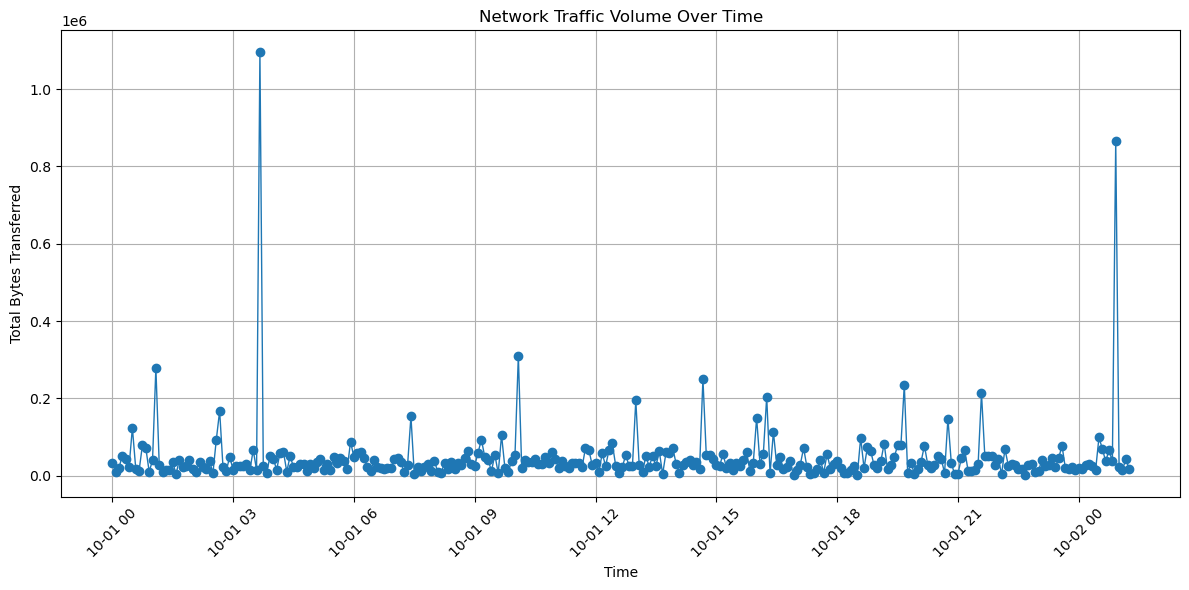

In [177]:
import pandas as pd
import matplotlib.pyplot as plt

data = pd.read_csv("network_traffic_cleaned.csv", parse_dates=["Timestamp"])

data["Time Interval"] = data["Timestamp"].dt.floor("5min")

traffic = data.groupby("Time Interval")["Bytes Transferred"].sum().reset_index()

plt.figure(figsize=(12, 6))

plt.plot(traffic["Time Interval"], traffic["Bytes Transferred"], marker="o", linestyle="-", linewidth=1)

plt.title("Network Traffic Volume Over Time")
plt.xlabel("Time")
plt.ylabel("Total Bytes Transferred")
plt.xticks(rotation=45)
plt.grid()
plt.tight_layout()

plt.show()


#  Create a bar chart comparing traffic volume across protocols

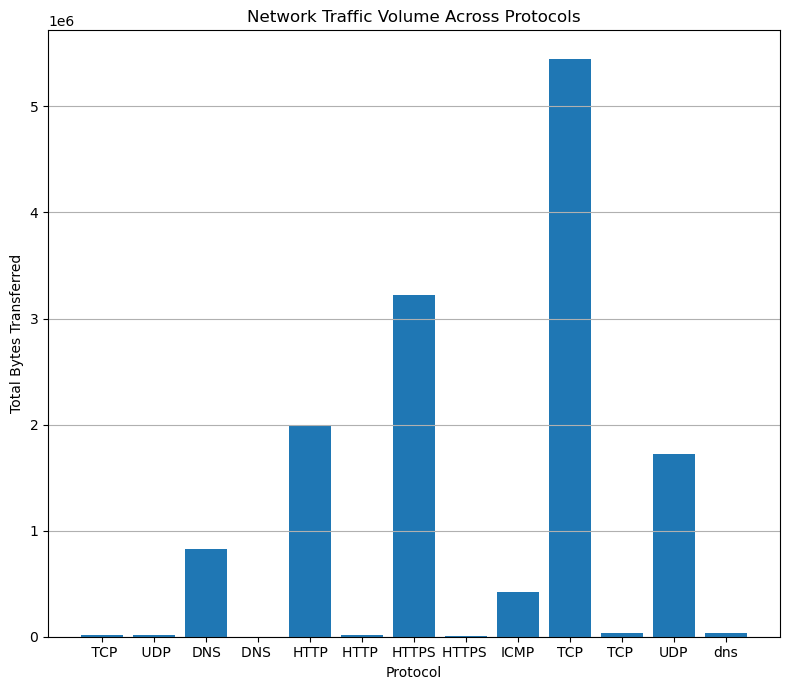

In [10]:
import pandas as pd
import matplotlib.pyplot as plt

data = pd.read_csv("network_traffic_cleaned.csv")

traffic = data.groupby("Protocol")["Bytes Transferred"].sum()

plt.figure(figsize=(8,7))

plt.bar(traffic.index, traffic.values)

plt.title("Network Traffic Volume Across Protocols")
plt.xlabel("Protocol")
plt.ylabel("Total Bytes Transferred")

plt.grid(axis="y")
plt.tight_layout()

plt.show()


# Create a histogram showing packet size distribution

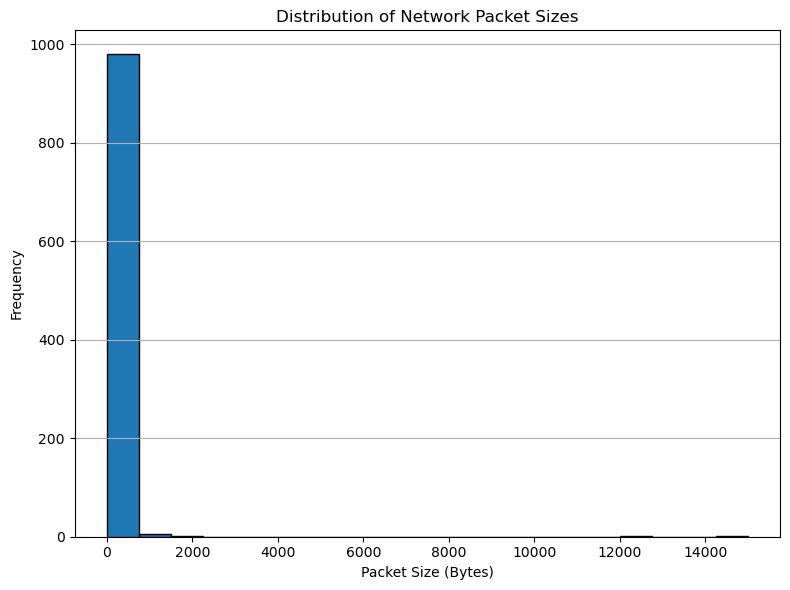

In [9]:
import pandas as pd
import matplotlib.pyplot as plt

data = pd.read_csv("network_traffic_cleaned.csv")

plt.figure(figsize=(8, 6))

plt.hist(data["Packet Size"].dropna(), bins=20, edgecolor="black")

plt.title("Distribution of Network Packet Sizes")
plt.xlabel("Packet Size (Bytes)")
plt.ylabel("Frequency")

plt.grid(axis="y")
plt.tight_layout()

plt.show()
